In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
healthcare = pd.read_csv("healthcare_dataset.csv")

In [3]:
healthcare_clean = healthcare.copy()

**Step 1: Remove Patient Name**

In [4]:
healthcare_clean = healthcare_clean.drop(columns=["Room Number"]) 

In [5]:
healthcare_clean.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

**Step 2: Convert data type columns to Discharge Date and Date of Admission**

In [6]:
healthcare_clean["Discharge Date"] = pd.to_datetime(healthcare_clean["Discharge Date"])
healthcare_clean["Date of Admission"] = pd.to_datetime(healthcare_clean["Date of Admission"])

**Step 3: Round Billing Amount to Two Places after the Decimal**

In [7]:
healthcare_clean["Billing Amount"] = healthcare_clean["Billing Amount"].round(2)

**Step 4**: 
One Hot Encode Gender, Blood Type Admission Type and Test Results 

In [8]:
dummie_variables = pd.get_dummies(healthcare_clean[["Gender", "Blood Type", "Admission Type", "Test Results"]])

In [9]:
healthcare_clean_encoded = pd.concat([healthcare_clean, dummie_variables], axis=1)

**Step 5**
Create a new column titled age range that captured the age range of the patients

In [10]:
def age_brackets(row):
    age_ranges = row["Age"]
    if age_ranges <= 17:
        return "Minors"
    elif 18 <= age_ranges <= 34:
        return "Young Adult"
    elif 35 <= age_ranges <= 49:
        return "Middle Aged"
    elif 50 <= age_ranges <= 64:
        return "Late Middle Aged"
    elif 65 <= age_ranges <= 74:
        return "Early Retirement"
    elif 75 <= age_ranges <= 89:
        return "Senior Citizen"
    else:
        "Aging Gracefully"

In [11]:
healthcare_clean_encoded["Age Ranges"] = healthcare_clean_encoded.apply(age_brackets, axis=1)
healthcare_clean_encoded.head(5)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,...,Blood Type_B-,Blood Type_O+,Blood Type_O-,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent,Test Results_Abnormal,Test Results_Inconclusive,Test Results_Normal,Age Ranges
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,...,True,False,False,False,False,True,False,False,True,Young Adult
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,...,False,False,False,False,True,False,False,True,False,Late Middle Aged
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,...,False,False,False,False,True,False,False,False,True,Senior Citizen
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78,...,False,True,False,True,False,False,True,False,False,Young Adult
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,...,False,False,False,False,False,True,True,False,False,Middle Aged


**Step 6: Create New Columns Admission Year and Discharge Year**
- return the year the patient was admitted and discharged
- return the month and year that the patient was admitted and discharged

In [12]:
healthcare_clean_encoded.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Admission Type', 'Discharge Date', 'Medication',
       'Test Results', 'Gender_Female', 'Gender_Male', 'Blood Type_A+',
       'Blood Type_A-', 'Blood Type_AB+', 'Blood Type_AB-', 'Blood Type_B+',
       'Blood Type_B-', 'Blood Type_O+', 'Blood Type_O-',
       'Admission Type_Elective', 'Admission Type_Emergency',
       'Admission Type_Urgent', 'Test Results_Abnormal',
       'Test Results_Inconclusive', 'Test Results_Normal', 'Age Ranges'],
      dtype='str')

**Step 7: Create New Column Admission Year, Discharge Year Admission Month Year and Discharge Month Year that have datetime conversions**

In [13]:
healthcare_clean_encoded["Admission Year"] = healthcare_clean_encoded["Date of Admission"].dt.year
healthcare_clean_encoded["Discharge Year"] = healthcare_clean_encoded["Discharge Date"].dt.year

healthcare_clean_encoded["Admission_Month_Year"] = healthcare_clean_encoded["Date of Admission"].dt.strftime('%B %Y')
healthcare_clean_encoded["Discharge_Month_Year"] = healthcare_clean_encoded["Discharge Date"].dt.strftime('%B %Y')

**Step 8** 
- Create New COlumn Is LifeStyle Condition boolean where if a medical condition is diabetes hypertension and obesity
- Create New COlumn Is Chronic Condition boolean where medical conditon is asthma, cancer or Arthritis

In [99]:
healthcare_clean_encoded["Is_Lifestyle_Condition"] = healthcare_clean_encoded["Medical Condition"].isin(["Diabetes", "Hypertension", "Obesity"])
healthcare_clean_encoded["Is_Chronic_Condition"] = healthcare_clean_encoded["Medical Condition"].isin(["Asthma", "Cancer", "Arthritis"])

In [100]:
healthcare_clean_encoded.head(5)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,...,Test Results_Abnormal,Test Results_Inconclusive,Test Results_Normal,Age Ranges,Admission Year,Discharge Year,Admission_Month_Year,Discharge_Month_Year,Is_Lifestyle_Condition,Is_Chronic_Condition
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,...,False,False,True,Young Adult,2024,2024,January 2024,February 2024,False,True
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,...,False,True,False,Late Middle Aged,2019,2019,August 2019,August 2019,True,False
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,...,False,False,True,Senior Citizen,2022,2022,September 2022,October 2022,True,False
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78,...,True,False,False,Young Adult,2020,2020,November 2020,December 2020,True,False
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,...,True,False,False,Middle Aged,2022,2022,September 2022,October 2022,False,True


In [101]:
healthcare_clean_encoded.isnull().sum()

Name                         0
Age                          0
Gender                       0
Blood Type                   0
Medical Condition            0
Date of Admission            0
Doctor                       0
Hospital                     0
Insurance Provider           0
Billing Amount               0
Admission Type               0
Discharge Date               0
Medication                   0
Test Results                 0
Gender_Female                0
Gender_Male                  0
Blood Type_A+                0
Blood Type_A-                0
Blood Type_AB+               0
Blood Type_AB-               0
Blood Type_B+                0
Blood Type_B-                0
Blood Type_O+                0
Blood Type_O-                0
Admission Type_Elective      0
Admission Type_Emergency     0
Admission Type_Urgent        0
Test Results_Abnormal        0
Test Results_Inconclusive    0
Test Results_Normal          0
Age Ranges                   0
Admission Year               0
Discharg

In [102]:
healthcare_clean_encoded.duplicated().sum()

np.int64(0)

In [103]:
duplicate = [healthcare_clean_encoded.duplicated()]
duplicate_rows = healthcare_clean_encoded[healthcare_clean_encoded.duplicated(keep=False)]

In [104]:
for col in healthcare_clean_encoded.columns:
    pct = healthcare_clean_encoded.duplicated(subset=[col]).mean()
    print(f"{col:<25} : {pct:.2%}")

Name                      : 0.00%
Age                       : 99.86%
Gender                    : 100.00%
Blood Type                : 99.98%
Medical Condition         : 99.99%
Date of Admission         : 96.34%
Doctor                    : 19.29%
Hospital                  : 20.22%
Insurance Provider        : 99.99%
Billing Amount            : 0.48%
Admission Type            : 99.99%
Discharge Date            : 96.28%
Medication                : 99.99%
Test Results              : 99.99%
Gender_Female             : 100.00%
Gender_Male               : 100.00%
Blood Type_A+             : 100.00%
Blood Type_A-             : 100.00%
Blood Type_AB+            : 100.00%
Blood Type_AB-            : 100.00%
Blood Type_B+             : 100.00%
Blood Type_B-             : 100.00%
Blood Type_O+             : 100.00%
Blood Type_O-             : 100.00%
Admission Type_Elective   : 100.00%
Admission Type_Emergency  : 100.00%
Admission Type_Urgent     : 100.00%
Test Results_Abnormal     : 100.00%
Test Re

**Return all Rows with Duplicate Names and Remove Them, then Remove Name as a column**

In [105]:
duplicate_rows_name = healthcare_clean_encoded[healthcare_clean_encoded.duplicated(subset=["Name"], keep="first")]

healthcare_clean_encoded = healthcare_clean_encoded.drop_duplicates(subset=["Name"], keep="first")

healthcare_clean_encoded.drop(columns=["Name"])

,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Admission Type,...,Test Results_Abnormal,Test Results_Inconclusive,Test Results_Normal,Age Ranges,Admission Year,Discharge Year,Admission_Month_Year,Discharge_Month_Year,Is_Lifestyle_Condition,Is_Chronic_Condition
0,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,Urgent,...,False,False,True,Young Adult,2024,2024,January 2024,February 2024,False,True
1,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,Emergency,...,False,True,False,Late Middle Aged,2019,2019,August 2019,August 2019,True,False
2,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,Emergency,...,False,False,True,Senior Citizen,2022,2022,September 2022,October 2022,True,False
3,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78,Elective,...,True,False,False,Young Adult,2020,2020,November 2020,December 2020,True,False
4,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,Urgent,...,True,False,False,Middle Aged,2022,2022,September 2022,October 2022,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,64,Male,O+,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.35,Emergency,...,False,True,False,Late Middle Aged,2022,2022,June 2022,July 2022,True,False
49996,69,Male,B+,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.58,Elective,...,True,False,False,Early Retirement,2020,2020,April 2020,April 2020,False,True
49997,73,Male,O-,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.15,Elective,...,True,False,False,Early Retirement,2023,2023,September 2023,September 2023,False,True
49998,81,Male,B-,Cancer,2020-10-13,Mary Bartlett,Sons Smith and,Blue Cross,34934.28,Elective,...,True,False,False,Senior Citizen,2020,2020,October 2020,October 2020,False,True


**Check for Outliers in the Age Column**

In [106]:
target_col = "Age"

Q1 = healthcare_clean_encoded["Age"].quantile(0.25)
Q3 = healthcare_clean_encoded["Age"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = healthcare_clean_encoded[(healthcare_clean_encoded[target_col] < lower_bound) | healthcare_clean_encoded[target_col] > upper_bound]

print(f"Total outliers found via IQR: {len(outliers_iqr)}")
print(f"Valid range for data: {lower_bound:.2f} to {upper_bound:.2f}")

Total outliers found via IQR: 0
Valid range for data: -14.50 to 117.50


**Check for Outliers in the Billing Amount Column**

In [107]:
target_col_1 = "Billing Amount"

Q1 = healthcare_clean_encoded["Billing Amount"].quantile(0.25)
Q3 = healthcare_clean_encoded["Billing Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR 
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = healthcare_clean_encoded[(healthcare_clean_encoded[target_col] < lower_bound) | healthcare_clean_encoded[target_col] > upper_bound]

print(f"Total outliers found via IQR: {len(outliers_iqr)}")
print(f"Valid range for data: {lower_bound:.2f} to {upper_bound:.2f}")

Total outliers found via IQR: 0
Valid range for data: -23568.62 to 74740.57


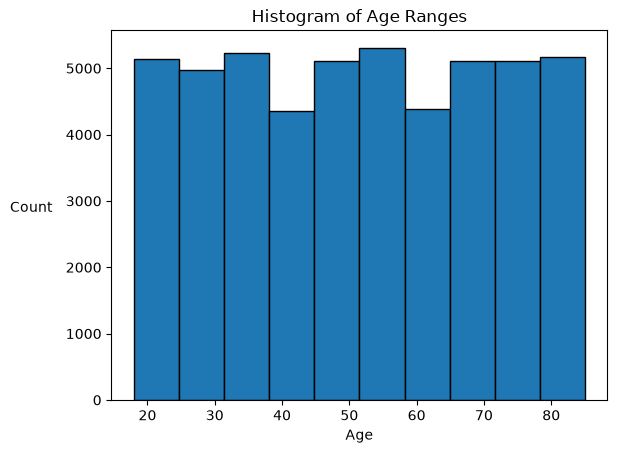

In [108]:
plt.hist(healthcare_clean_encoded["Age"], bins=10, edgecolor="black")
plt.title("Histogram of Age Ranges")
plt.xlabel("Age")
plt.ylabel("Count", rotation=0, labelpad=25)
plt.show()

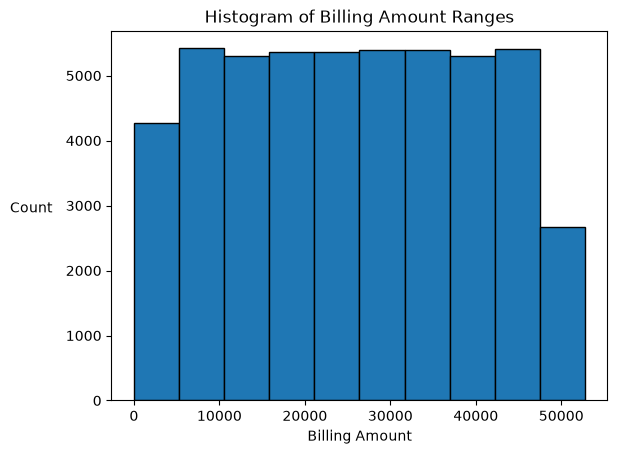

In [109]:
plt.hist(healthcare_clean_encoded["Billing Amount"], bins=10, edgecolor="black")
plt.title("Histogram of Billing Amount Ranges")
plt.xlabel("Billing Amount")
plt.ylabel("Count", rotation=0, labelpad=25)
plt.show()

In [110]:
healthcare_clean_encoded[["Billing Amount", "Age"]].describe()

,Billing Amount,Age
count,49896.000000,49896.000000
mean,25605.849513,51.579024
std,14183.597213,19.580297
min,9.240000,18.000000
25%,13297.330000,35.000000
50%,25593.875000,52.000000
75%,37874.627500,68.000000
max,52764.280000,85.000000


**Filter out values with Billing Amount less than 0**

In [111]:
healthcare_clean_encoded = healthcare_clean_encoded[healthcare_clean_encoded["Billing Amount"] >= 0]

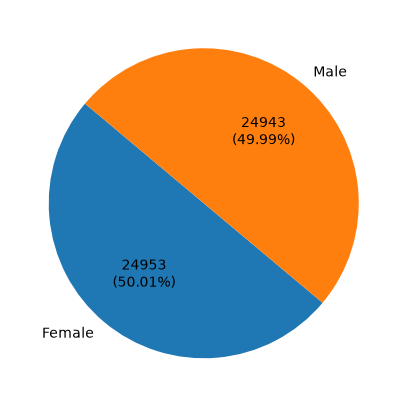

In [112]:
gender_counts = healthcare_clean_encoded["Gender"].value_counts()
gender_sum = gender_counts.sum()

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * gender_sum / 100.0))
        return f'{val}\n({pct:.2f}%)'
    return my_autopct

plt.figure(figsize=(5, 8))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct=make_autopct(gender_counts),
    startangle=140
)
plt.show()

In [113]:
year_medical_conditions = healthcare_clean_encoded.groupby(["Medical Condition", "Admission Year"]).size().unstack(fill_value=0)
year_medical_conditions

Admission Year,2019,2020,2021,2022,2023,2024
Medical Condition,,,,,,
Arthritis,1090,1696,1660,1684,1674,625
Asthma,1154,1633,1646,1602,1604,614
Cancer,1139,1715,1582,1636,1645,559
Diabetes,1124,1637,1633,1737,1669,564
Hypertension,1060,1705,1684,1651,1660,540
Obesity,1049,1755,1659,1600,1659,552


<Figure size 1200x600 with 0 Axes>

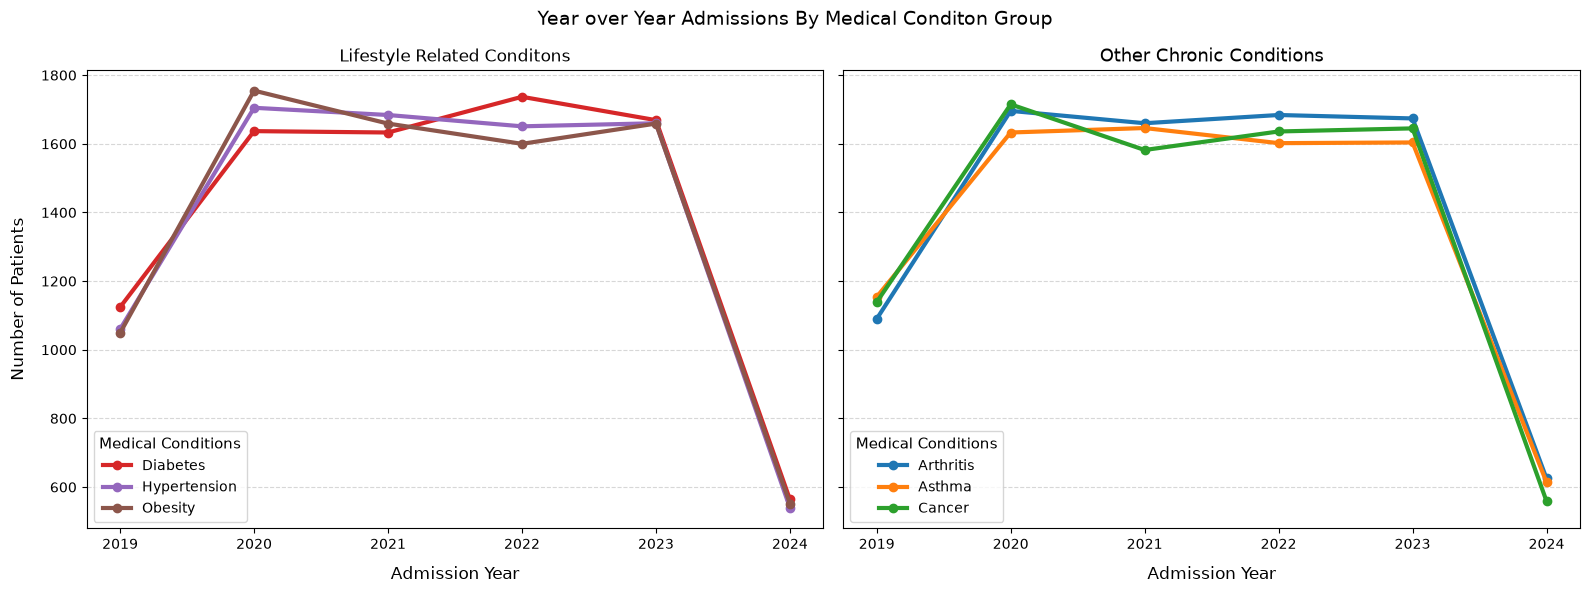

In [114]:
plt.figure(figsize=(12, 6))
colors = plt.colormaps["tab10"]

group1 = ["Diabetes", "Hypertension", "Obesity"] # lifestyle related
group2 = ["Arthritis", "Asthma", "Cancer"] # other chronic conditions

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for condition in group1:
    i = list(year_medical_conditions.index).index(condition)
    axes[0].plot(year_medical_conditions.columns,
                year_medical_conditions.loc[condition],
                marker="o", linewidth=3, color=colors(i), label=condition)
    
axes[0].set_title("Lifestyle Related Conditons", fontsize=12)
axes[0].set_xlabel("Admission Year", fontsize=12, labelpad=10)
axes[0].set_ylabel("Number of Patients", fontsize=12, labelpad=10)
axes[0].legend(title="Medical Conditions", title_fontsize=11)
axes[0].set_xticks(year_medical_conditions.columns)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

for condition in group2:
    i = list(year_medical_conditions.index).index(condition)
    axes[1].plot(year_medical_conditions.columns,
                year_medical_conditions.loc[condition],
                marker="o", linewidth=3, color=colors(i), label=condition)
    
axes[1].set_title("Other Chronic Conditions", fontsize=13)
axes[1].set_xlabel("Admission Year", fontsize=12, labelpad=10)
axes[1].legend(title="Medical Conditions", title_fontsize=11)
axes[1].set_xticks(year_medical_conditions.columns)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

fig.suptitle("Year over Year Admissions By Medical Conditon Group", fontsize=14)
plt.tight_layout()
plt.show()

In [115]:
gender_year

Admission Year,2019,2020,2021,2022,2023,2024
Gender,,,,,,
Female,3329,5042,4994,4919,5001,1722
Male,3306,5113,4889,5012,4926,1739


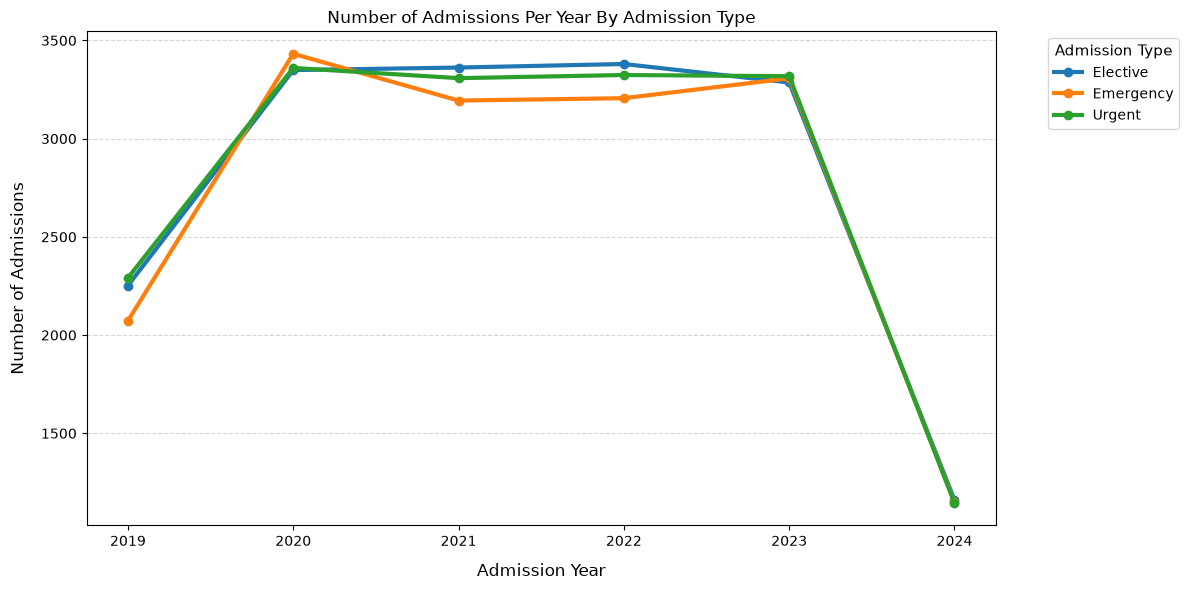

In [116]:
admission_type_year = healthcare_clean_encoded.groupby(["Admission Type", "Admission Year"]).size().unstack(fill_value=0)

colors = plt.colormaps["tab10"]

plt.figure(figsize=(12, 6))
for i, admission_type in enumerate(admission_type_year.index):
    plt.plot(admission_type_year.columns,
             admission_type_year.loc[admission_type],
             marker="o", linewidth=3, color=colors(i), label=admission_type)

plt.title("Number of Admissions Per Year By Admission Type")
plt.xlabel("Admission Year", fontsize=12, labelpad=10)
plt.ylabel("Number of Admissions", fontsize=12, labelpad=10)
plt.legend(title="Admission Type", title_fontsize=11, loc="upper left", bbox_to_anchor=(1.05, 1))
plt.xticks(admission_type_year.columns)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [117]:
medical_admission = healthcare_clean_encoded.pivot_table(index="Medical Condition", columns=["Admission Type"], values="Admission Year", aggfunc="count")
medical_admission

Admission Type,Elective,Emergency,Urgent
Medical Condition,,,
Arthritis,2819,2785,2825
Asthma,2804,2684,2765
Cancer,2813,2704,2759
Diabetes,2763,2707,2894
Hypertension,2874,2676,2750
Obesity,2717,2804,2753


In [118]:
medical_condition_blood_type = healthcare_clean_encoded.pivot_table(index="Blood Type", columns=["Medical Condition"], values="Admission Year", aggfunc="count", fill_value=0)
medical_condition_blood_type

Medical Condition,Arthritis,Asthma,Cancer,Diabetes,Hypertension,Obesity
Blood Type,,,,,,
A+,1026,1010,1053,1080,1022,1039
A-,1049,1050,1014,1054,1060,1019
AB+,1029,1071,1001,1059,1089,1032
AB-,1067,1015,1073,1030,1025,1034
B+,1076,1012,1078,1071,990,1042
B-,1063,1006,1016,1025,1042,1067
O+,1081,1039,1005,1041,1046,1011
O-,1038,1050,1036,1004,1026,1030


In [119]:
blood_type_gender = healthcare_clean_encoded.pivot_table(index="Gender", columns=["Blood Type"], values="Admission Year", aggfunc="count", fill_value=0)
blood_type_gender

Blood Type,A+,A-,AB+,AB-,B+,B-,O+,O-
Gender,,,,,,,,
Female,3202,3080,3125,3113,3039,3117,3115,3162
Male,3028,3166,3156,3131,3230,3102,3108,3022


In [120]:
insurance_admissions = healthcare_clean_encoded.pivot_table(index="Medical Condition", columns=["Insurance Provider"], values="Admission Year", aggfunc="count", fill_value=0)
insurance_admissions

Insurance Provider,Aetna,Blue Cross,Cigna,Medicare,UnitedHealthcare
Medical Condition,,,,,
Arthritis,1658,1691,1701,1685,1694
Asthma,1587,1657,1691,1641,1677
Cancer,1636,1617,1682,1676,1665
Diabetes,1665,1680,1673,1726,1620
Hypertension,1671,1633,1656,1646,1694
Obesity,1606,1707,1665,1663,1633


In [121]:
order1 = healthcare_clean_encoded["Age Ranges"].value_counts().index
order1

Index(['Young Adult', 'Late Middle Aged', 'Middle Aged', 'Senior Citizen',
       'Early Retirement'],
      dtype='str', name='Age Ranges')

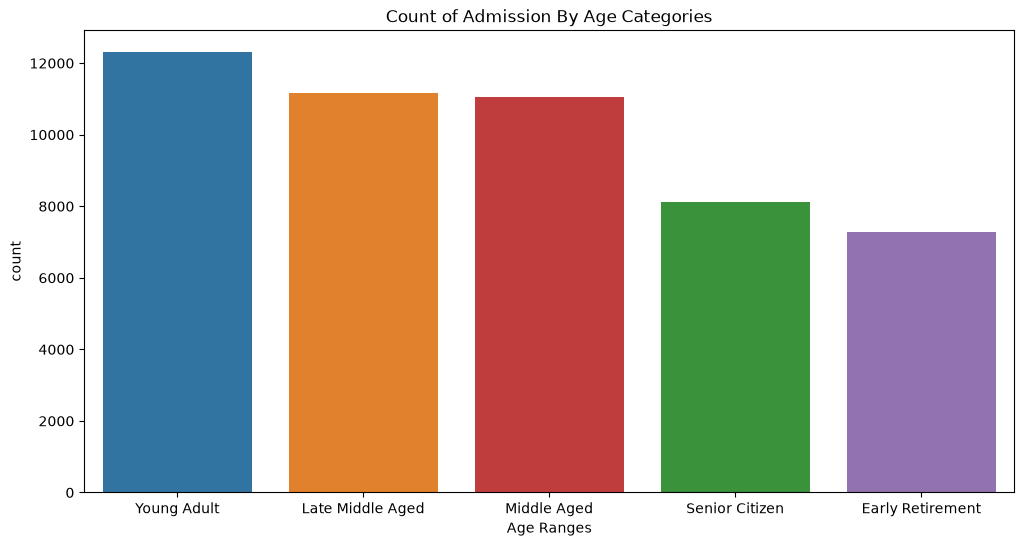

In [122]:
plt.figure(figsize=(12, 6))
sns.countplot(data=healthcare_clean_encoded, x="Age Ranges", hue="Age Ranges", order=order1)
plt.title("Count of Admission By Age Categories")
plt.show()

In [123]:
healthcare_clean_encoded["Insurance Provider"].value_counts()

Insurance Provider
Cigna               10068
Medicare            10037
Blue Cross           9985
UnitedHealthcare     9983
Aetna                9823
Name: count, dtype: int64

In [124]:
healthcare_clean_encoded["Blood Type"].value_counts()

Blood Type
AB+    6281
B+     6269
A-     6246
AB-    6244
A+     6230
O+     6223
B-     6219
O-     6184
Name: count, dtype: int64

In [125]:
healthcare_clean_encoded["Medical Condition"].value_counts()

Medical Condition
Arthritis       8429
Diabetes        8364
Hypertension    8300
Cancer          8276
Obesity         8274
Asthma          8253
Name: count, dtype: int64

In [128]:
chronic_condition = healthcare_clean_encoded[healthcare_clean_encoded["Is_Chronic_Condition"] == True]

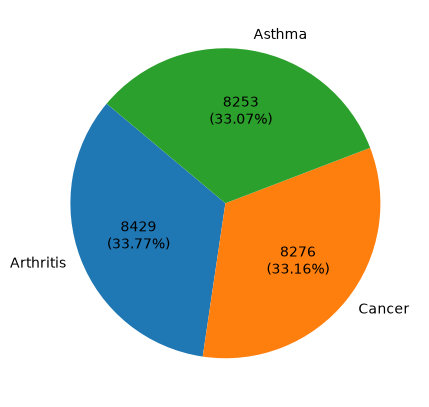

In [131]:
chronic_condition_counts = chronic_condition["Medical Condition"].value_counts()
chronic_condition_sum = chronic_condition_counts.sum()

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * chronic_condition_sum / 100.0))
        return f'{val}\n({pct:.2f}%)'
    return my_autopct

plt.figure(figsize=(5, 8))
plt.pie(
    chronic_condition_counts,
    labels=chronic_condition_counts.index,
    autopct=make_autopct(chronic_condition_counts),
    startangle=140
)
plt.show()

In [132]:
lifestyle_condition = healthcare_clean_encoded[healthcare_clean_encoded["Is_Lifestyle_Condition"] == True]

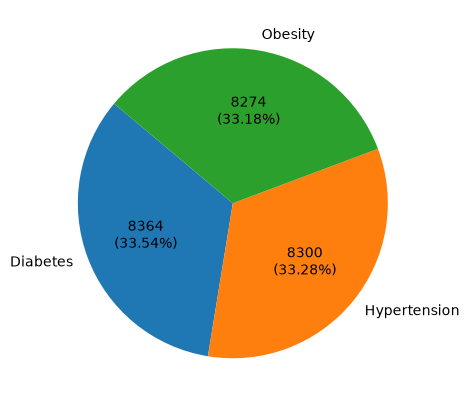

In [133]:
lifestyle_condition_counts = lifestyle_condition["Medical Condition"].value_counts()
lifestyle_condition_sum = lifestyle_condition_counts.sum()

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * lifestyle_condition_sum / 100.0))
        return f'{val}\n({pct:.2f}%)'
    return my_autopct

plt.figure(figsize=(5, 8))
plt.pie(
    lifestyle_condition_counts,
    labels=lifestyle_condition_counts.index,
    autopct=make_autopct(lifestyle_condition_counts),
    startangle=140
)
plt.show()